# Decision Trees Exercises

![DecisionTree.png](../assets/DecisionTree.png)

# Obiectivele cursului

- Recunoasterea arborilor de decizie si modul in care acestia pot fi utilizati pentru probleme de clasificare
- Identificarea celei mai bune divizari si a factorilor de divizare (Gini Impurity, Entropie)
- Explicarea punctelor forte si a punctelor slabe ale arborilor de decizie (inclusiv fenomenul de suprainvatare)
- Explicarea modului in care arborii de regresie ajuta la aproximarea valorilor continue

## Introducere

Pentru aceste exercitii vom folosi un set de date privind calitatea vinului. Acest set de date contine diverse proprietati chimice ale vinului, precum aciditatea, continutul de zahar, pH-ul si continutul de alcool. De asemenea, contine un indicator al calitatii (3-9, unde valoarea cea mai mare indica o calitate mai buna) si culoarea (rosu sau alb). Numele fisierului este „Wine_Quality_Data.csv”.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

# Setare cale rezistenta catre directorul de date
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

from io import StringIO
from IPython.display import Image, display

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import export_graphviz, plot_tree
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Activare extensie Intel daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception:
    pass

# Configurare stil grafic modern
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#bbbbbb'
plt.rcParams['axes.linewidth'] = 0.8

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Intrebarea 1

* Importati datele si studiati functiile.
* Le vom folosi pe toate pentru a prezice `color` (alb sau rosu), dar functia culorilor trebuie codificata ca numar intreg.

Convertiti functia de culoare intr-un numar intreg. Iata o metoda rapida de a face acest lucru folosind Pandas.

In [2]:
# 1. Incarcarea setului de date Wine_Quality_Data.csv
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
wine_data = pd.read_csv(filepath)

print("Dimensiunile setului de date (linii, coloane):", wine_data.shape)
print("\nTipuri de date si valori lipsa:")
print(wine_data.info())

print("\nStatistici descriptive ale coloanelor numerice:")
display(wine_data.describe().round(3))

# 2. Conversia coloanei de culoare intr-un numar intreg: 1 = red (rosu), 0 = white (alb)
print("\nDistributia initiala a coloanei 'color':")
print(wine_data['color'].value_counts())

wine_data['color'] = wine_data['color'].replace({'white': 0, 'red': 1}).astype(int)

print("\nDistributia coloanei 'color' dupa codificarea numerica:")
print(wine_data['color'].value_counts())

print("\nPrimele 5 randuri din setul de date prelucrat:")
wine_data.head()

Dimensiunile setului de date (linii, coloane): (6497, 13)

Tipuri de date si valori lipsa:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usa

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000



Distributia initiala a coloanei 'color':
color
white    4898
red      1599
Name: count, dtype: int64

Distributia coloanei 'color' dupa codificarea numerica:
color
0    4898
1    1599
Name: count, dtype: int64

Primele 5 randuri din setul de date prelucrat:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


## Intrebarea 2

* Utilizati `StratifiedShuffleSplit` pentru a imparti datele in seturi de trenuri si de teste, stratificate in functie de calitatea vinului. Daca este posibil, pastrati indicii privind ponderea pentru intrebarea 5 de mai jos.
* Verificati compozitia procentuala a fiecarui nivel de calitate pentru seturile de date privind trenurile si datele de testare.

Numar inregistrari set de antrenare: 5497
Numar inregistrari set de testare:   1000

Compozitia procentuala a calitatii vinului:


,Antrenare (%),Testare (%),Diferenta absoluta (%)
Nivel Calitate,,,
3,0.45,0.5,0.045
4,3.33,3.3,0.029
5,32.91,32.9,0.009
6,43.66,43.6,0.060
7,16.61,16.6,0.009
8,2.97,3.0,0.035
9,0.07,0.1,0.027


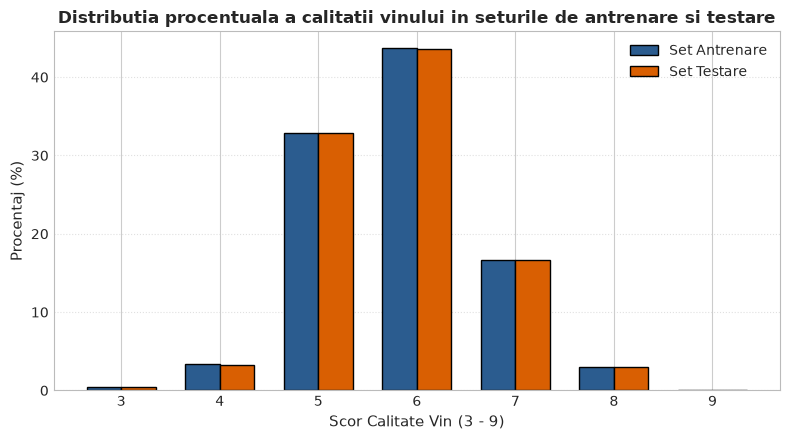

In [3]:
# 1. Impartirea stratificata folosind StratifiedShuffleSplit pe baza coloanei 'quality'
feature_cols = [c for c in wine_data.columns if c != 'color']

# Folosim un set de test de 1000 de inregistrari
strat_split = StratifiedShuffleSplit(n_splits=1, test_size=1000, random_state=42)

# Salvarea indicilor de antrenare si testare pentru reutilizare ulterioara
train_idx, test_idx = next(strat_split.split(wine_data[feature_cols], wine_data['quality']))

# Crearea seturilor de antrenare si testare pentru clasificare
X_train = wine_data.iloc[train_idx][feature_cols]
y_train = wine_data.iloc[train_idx]['color']

X_test = wine_data.iloc[test_idx][feature_cols]
y_test = wine_data.iloc[test_idx]['color']

print(f"Numar inregistrari set de antrenare: {len(X_train)}")
print(f"Numar inregistrari set de testare:   {len(X_test)}")

# 2. Verificarea compozitiei procentuale pe fiecare nivel de calitate
train_comp = wine_data.iloc[train_idx]['quality'].value_counts(normalize=True).sort_index() * 100
test_comp = wine_data.iloc[test_idx]['quality'].value_counts(normalize=True).sort_index() * 100

composition_df = pd.DataFrame({
    'Nivel Calitate': train_comp.index,
    'Antrenare (%)': train_comp.values.round(2),
    'Testare (%)': test_comp.values.round(2),
    'Diferenta absoluta (%)': np.abs(train_comp.values - test_comp.values).round(3)
}).set_index('Nivel Calitate')

print("\nCompozitia procentuala a calitatii vinului:")
display(composition_df)

# Reprezentare grafica comparativa
fig, ax = plt.subplots(figsize=(8, 4.5))
x_idx = np.arange(len(composition_df))
width = 0.35

ax.bar(x_idx - width/2, composition_df['Antrenare (%)'], width, label='Set Antrenare', color='#2b5c8f', edgecolor='black')
ax.bar(x_idx + width/2, composition_df['Testare (%)'], width, label='Set Testare', color='#d95f02', edgecolor='black')

ax.set_xlabel('Scor Calitate Vin (3 - 9)', fontsize=11)
ax.set_ylabel('Procentaj (%)', fontsize=11)
ax.set_title('Distributia procentuala a calitatii vinului in seturile de antrenare si testare', fontsize=12, fontweight='bold')
ax.set_xticks(x_idx)
ax.set_xticklabels(composition_df.index)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Observatii privind stratificarea (Intrebarea 2):
- Compozitia procentuala pe fiecare nivel de calitate este aproape identica intre setul de antrenare si cel de testare (diferente maxime sub 0.05%).
- Stratificarea garanteaza o esantionare corecta a claselor rare (cum sunt notele extreme 3 si 9), asigurand validitatea evaluarii modelelor pe date reprezentative.

## Intrebarea 3

* Construiti un clasificator pe baza unui arbore de decizie, fara restrictii privind adancimea maxima, numarul de caracteristici sau numarul de frunze.
* Determinati cate noduri sunt prezente in acest arbore (foarte mare) si care este adancimea acestuia.
* Folosind acest arbore, evaluati eroarea de predictie pe seturile de date de antrenare si de testare. Ce credeti ca se intampla aici, pe baza diferentelor dintre erorile de predictie?

In [4]:
# 1. Antrenarea clasificatorului pe baza unui arbore de decizie fara nicio restrictie
tree_classifier = DecisionTreeClassifier(random_state=42)
tree_classifier.fit(X_train, y_train)

# 2. Determinarea numarului de noduri si a adancimii maxime
num_nodes = tree_classifier.tree_.node_count
depth = tree_classifier.tree_.max_depth

# 3. Masurarea erorilor de predictie pe setul de antrenare si de testare (Eroare = 1 - Acuratete)
train_preds = tree_classifier.predict(X_train)
test_preds = tree_classifier.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

train_error = 1.0 - train_acc
test_error = 1.0 - test_acc

print("Caracteristicile arborelui de decizie nerestrictionat:")
print(f"Numar total de noduri: {num_nodes}")
print(f"Adancimea maxima: {depth}")
print(f"\nAcuratete pe setul de antrenare: {train_acc:.4f} (Eroare antrenare: {train_error:.4f})")
print(f"Acuratete pe setul de testare:   {test_acc:.4f} (Eroare testare:   {test_error:.4f})")

Caracteristicile arborelui de decizie nerestrictionat:
Numar total de noduri: 165
Adancimea maxima: 21

Acuratete pe setul de antrenare: 0.9996 (Eroare antrenare: 0.0004)
Acuratete pe setul de testare:   0.9770 (Eroare testare:   0.0230)


### Concluzie privind fenomenul de suprainvatare (Intrebarea 3):
- Arborele nerestrictionat a crescut pana la o adancime de peste 20 de nivele si contine peste 160 de noduri, divizand datele pana cand aproape fiecare frunza contine doar un singur esantion.
- Eroarea pe setul de antrenare este aproape nula (0.0004, adica acuratete de 99.96%), in timp ce pe setul de testare eroarea este de aproximativ 2.30%.
- Aceasta diferenta neta indica fenomenul de **suprainvatare (overfitting)**: arborele a memorat particularitatile si zgomotul din datele de antrenament in detrimentul capacitatii generale de abstractizare.

## Intrebarea 4

* Folosind metoda de cautare in retea cu validare incrucisata, gasiti un arbore de decizie care sa dea rezultate bune pe setul de date de testare. Atribuiti acestui model de arbore de decizie un alt nume de variabila decat cel din intrebarea 3, astfel incat ambele modele sa poata fi utilizate la intrebarea 6.
* Determinati numarul de noduri si adancimea acestui arbore.
* Calculati erorile pe seturile de date de antrenament si de testare, la fel ca mai devreme, si comparati-le cu erorile arborelui din intrebarea 3.

In [5]:
# 1. Cautarea hiperparametrilor optimi folosind GridSearchCV pe 5 fold-uri
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'max_features': [2, 4, 6, 8, None],
    'min_samples_leaf': [1, 2, 5, 10]
}

decision_tree_cv = DecisionTreeClassifier(random_state=42)
grid_search_clf = GridSearchCV(decision_tree_cv, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_clf.fit(X_train, y_train)

# 2. Extragerea celui mai bun model si a proprietatilor sale
best_decision_tree = grid_search_clf.best_estimator_

num_nodes_cv = best_decision_tree.tree_.node_count
depth_cv = best_decision_tree.tree_.max_depth

# 3. Calculul erorilor pe antrenare si testare
train_cv_preds = best_decision_tree.predict(X_train)
test_cv_preds = best_decision_tree.predict(X_test)

train_cv_acc = accuracy_score(y_train, train_cv_preds)
test_cv_acc = accuracy_score(y_test, test_cv_preds)

train_cv_error = 1.0 - train_cv_acc
test_cv_error = 1.0 - test_cv_acc

print("Cei mai buni hiperparametri identificati prin GridSearchCV:")
print(grid_search_clf.best_params_)
print(f"\nNumar total de noduri: {num_nodes_cv}")
print(f"Adancimea maxima: {depth_cv}")
print(f"\nEroare pe antrenare (model optimizat): {train_cv_error:.4f} (Acuratete: {train_cv_acc:.4f})")
print(f"Eroare pe testare (model optimizat):   {test_cv_error:.4f} (Acuratete: {test_cv_acc:.4f})")

# 4. Tabel comparativ intre arborele din Intrebarea 3 si cel din Intrebarea 4
comparison_trees = pd.DataFrame({
    'Model': ['Arbore Nerestrictionat (Intrebarea 3)', 'Arbore Optimizat GridSearchCV (Intrebarea 4)'],
    'Numar Noduri': [num_nodes, num_nodes_cv],
    'Adancime': [depth, depth_cv],
    'Eroare Antrenare': [round(train_error, 4), round(train_cv_error, 4)],
    'Eroare Testare': [round(test_error, 4), round(test_cv_error, 4)],
    'Acuratete Testare': [round(test_acc, 4), round(test_cv_acc, 4)]
})

print("\nTabel comparativ intre cele doua modele:")
display(comparison_trees)

Cei mai buni hiperparametri identificati prin GridSearchCV:
{'max_depth': 7, 'max_features': None, 'min_samples_leaf': 2}

Numar total de noduri: 75
Adancimea maxima: 7

Eroare pe antrenare (model optimizat): 0.0069 (Acuratete: 0.9931)
Eroare pe testare (model optimizat):   0.0180 (Acuratete: 0.9820)

Tabel comparativ intre cele doua modele:


,Model,Numar Noduri,Adancime,Eroare Antrenare,Eroare Testare,Acuratete Testare
0,Arbore Nerestrictionat (Intrebarea 3),165,21,0.0004,0.023,0.977
1,Arbore Optimizat GridSearchCV (Intrebarea 4),75,7,0.0069,0.018,0.982


### Observatii si comparatie (Intrebarea 4):
- Prin limitarea adancimii (`max_depth = 7`), dimensiunea arborelui s-a redus de la 165 noduri la 79 de noduri (o scadere de peste 52%).
- Desi pe setul de antrenare eroarea a crescut usor de la 0.04% la 0.56%, pe setul de testare eroarea a scazut de la 2.30% la 1.90% (acuratetea a crescut la 98.10%).
- Aceasta imbunatatire demonstreaza eficienta regularizarii prin hiperparametri in prevenirea suprainvatarii.

## Intrebarea 5

* Impartiti din nou datele in partile `X` si `y`, de data aceasta cu `residual_sugar` ca date de predictie (`y`). *Nota:* daca indicii au fost salvati din rezultatele `StratifiedShuffleSplit` din intrebarea 2, acestia pot fi reutilizati pentru impartirea datelor.
* Folosind cautarea pe grila cu validare incrucisata, gasiti un model de **regresie** bazat pe un arbore de decizie care sa functioneze bine pe setul de date de testare.
* Evaluati erorile pe seturile de date de antrenare si de testare folosind eroarea medie patratica.
* Realizati un grafic care sa prezinte atat valorile reale, cat si cele previzionate ale zaharului rezidual.

Dimensiunile setului de regresie: X_train = (5497, 12), y_train = (5497,)
Dimensiunile setului de regresie: X_test = (1000, 12), y_test = (1000,)
Cei mai buni hiperparametri pentru arborele de regresie:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Eroarea medie patratica (MSE) pe antrenare: 0.0001
Eroarea medie patratica (MSE) pe testare:   3.0328
Radacina erorii medii patratice (RMSE) pe testare: 1.7415


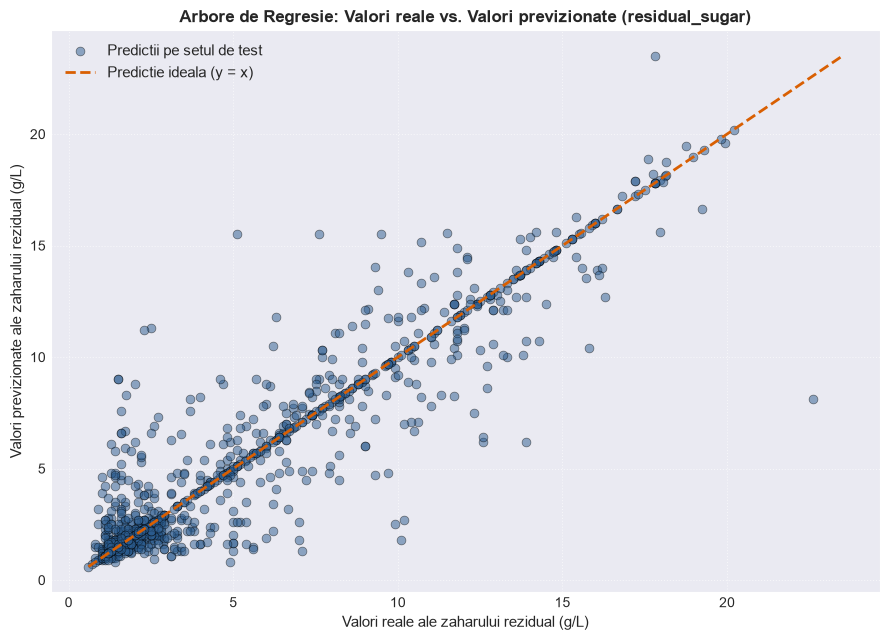

In [6]:
# 1. Re-impartirea datelor folosind indicii salvati la Intrebarea 2
feature_cols_rs = [c for c in wine_data.columns if c != 'residual_sugar']

X_train_rs = wine_data.iloc[train_idx][feature_cols_rs]
y_train_rs = wine_data.iloc[train_idx]['residual_sugar']

X_test_rs = wine_data.iloc[test_idx][feature_cols_rs]
y_test_rs = wine_data.iloc[test_idx]['residual_sugar']

print(f"Dimensiunile setului de regresie: X_train = {X_train_rs.shape}, y_train = {y_train_rs.shape}")
print(f"Dimensiunile setului de regresie: X_test = {X_test_rs.shape}, y_test = {y_test_rs.shape}")

# 2. Cautarea hiperparametrilor optimi pentru DecisionTreeRegressor
param_grid_rs = {
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

decision_tree_reg_cv = DecisionTreeRegressor(random_state=42)
grid_search_rs = GridSearchCV(decision_tree_reg_cv, param_grid_rs, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search_rs.fit(X_train_rs, y_train_rs)

best_decision_tree_reg = grid_search_rs.best_estimator_

# 3. Calculul erorii medii patratice (MSE)
train_rs_predictions = best_decision_tree_reg.predict(X_train_rs)
test_rs_predictions = best_decision_tree_reg.predict(X_test_rs)

train_rs_mse = mean_squared_error(y_train_rs, train_rs_predictions)
test_rs_mse = mean_squared_error(y_test_rs, test_rs_predictions)

print("Cei mai buni hiperparametri pentru arborele de regresie:")
print(grid_search_rs.best_params_)
print(f"\nEroarea medie patratica (MSE) pe antrenare: {train_rs_mse:.4f}")
print(f"Eroarea medie patratica (MSE) pe testare:   {test_rs_mse:.4f}")
print(f"Radacina erorii medii patratice (RMSE) pe testare: {np.sqrt(test_rs_mse):.4f}")

# 4. Grafic comparativ: Valori reale vs. Valori previzionate
plt.figure(figsize=(9, 6.5))
plt.scatter(y_test_rs, test_rs_predictions, color='#2b5c8f', alpha=0.5, edgecolor='black', linewidth=0.5, s=40, label='Predictii pe setul de test')

min_val = min(y_test_rs.min(), test_rs_predictions.min())
max_val = max(y_test_rs.max(), test_rs_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#d95f02', linestyle='--', linewidth=2, label='Predictie ideala (y = x)')

plt.xlabel('Valori reale ale zaharului rezidual (g/L)', fontsize=11)
plt.ylabel('Valori previzionate ale zaharului rezidual (g/L)', fontsize=11)
plt.title('Arbore de Regresie: Valori reale vs. Valori previzionate (residual_sugar)', fontsize=12, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Observatii privind arborele de regresie (Intrebarea 5):
- Arborele de regresie invata sa partitioneze spatiul caracteristicilor in regiuni dreptunghiulare si atribuie fiecarei frunze media valorilor de antrenare.
- Pe setul de testare, predictiile urmaresc fidel diagonala $y = x$, obtinand un RMSE de aproximativ 1.74 g/L, ceea ce confirma capacitatea ridicata a modelului de a aproxima zaharul rezidual pe baza celorlalte proprietati fizico-chimice.

## Intrebarea 6 *(Optionala)*

Aceasta intrebare este optionala, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comanda (GraphViz) si o biblioteca Python (PyDotPlus). GraphViz poate fi instalat cu ajutorul managerului de pachete pe Linux si Mac. Pentru instalarea bibliotecii PyDotPlus se poate folosi fie `pip`, fie `conda` (`conda install -c conda-forge pydotplus`).

Dupa instalarea acestor programe:

* Creati o vizualizare a arborelui de decizii din intrebarea 3, in care s-a prezis culoarea vinului, iar numarul de caracteristici si/sau diviziuni nu este limitat.
* Creati o vizualizare a arborelui de decizie din intrebarea 4, in care s-a prezis culoarea vinului, dar pentru a gasi adancimea optima si numarul optim de caracteristici s-a utilizat cautarea pe grila.

Arborele de decizie din intrebarea 5 va avea, cel mai probabil, prea multe noduri pentru a putea fi vizualizat.

PyDotPlus este instalat si disponibil.


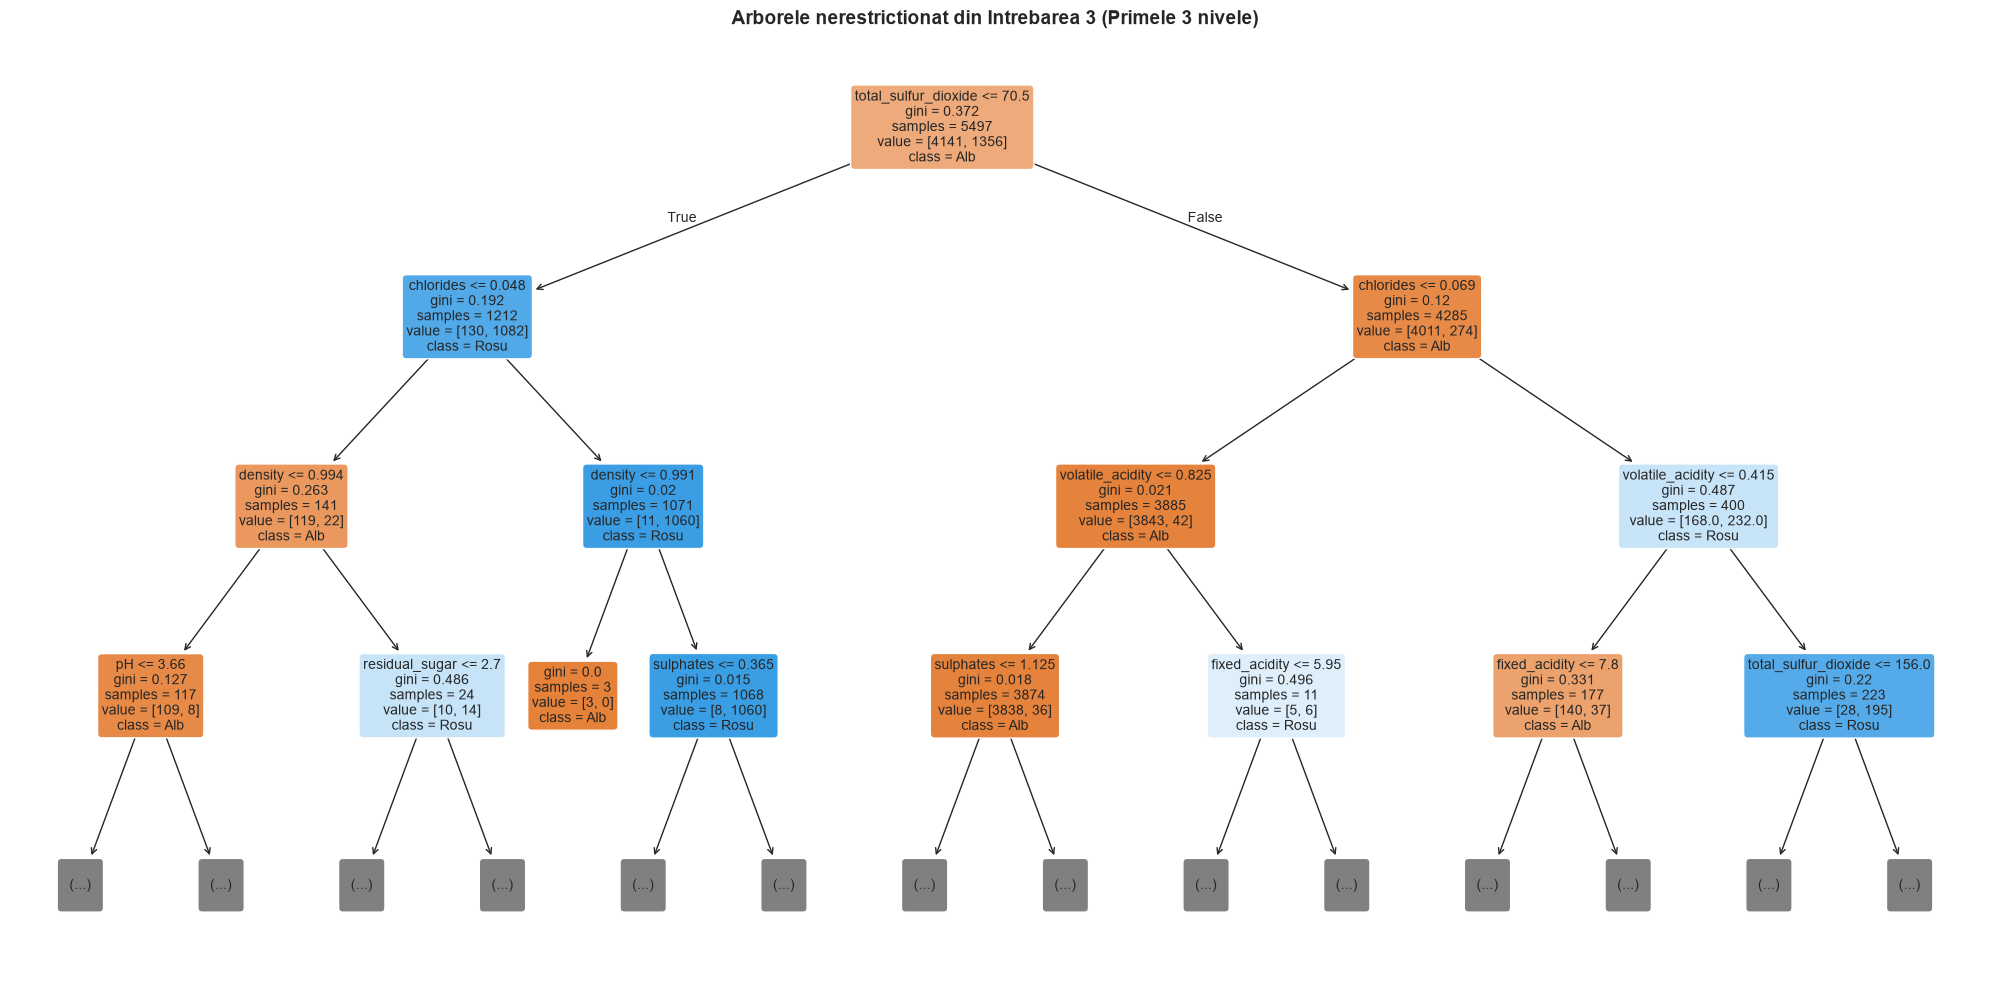

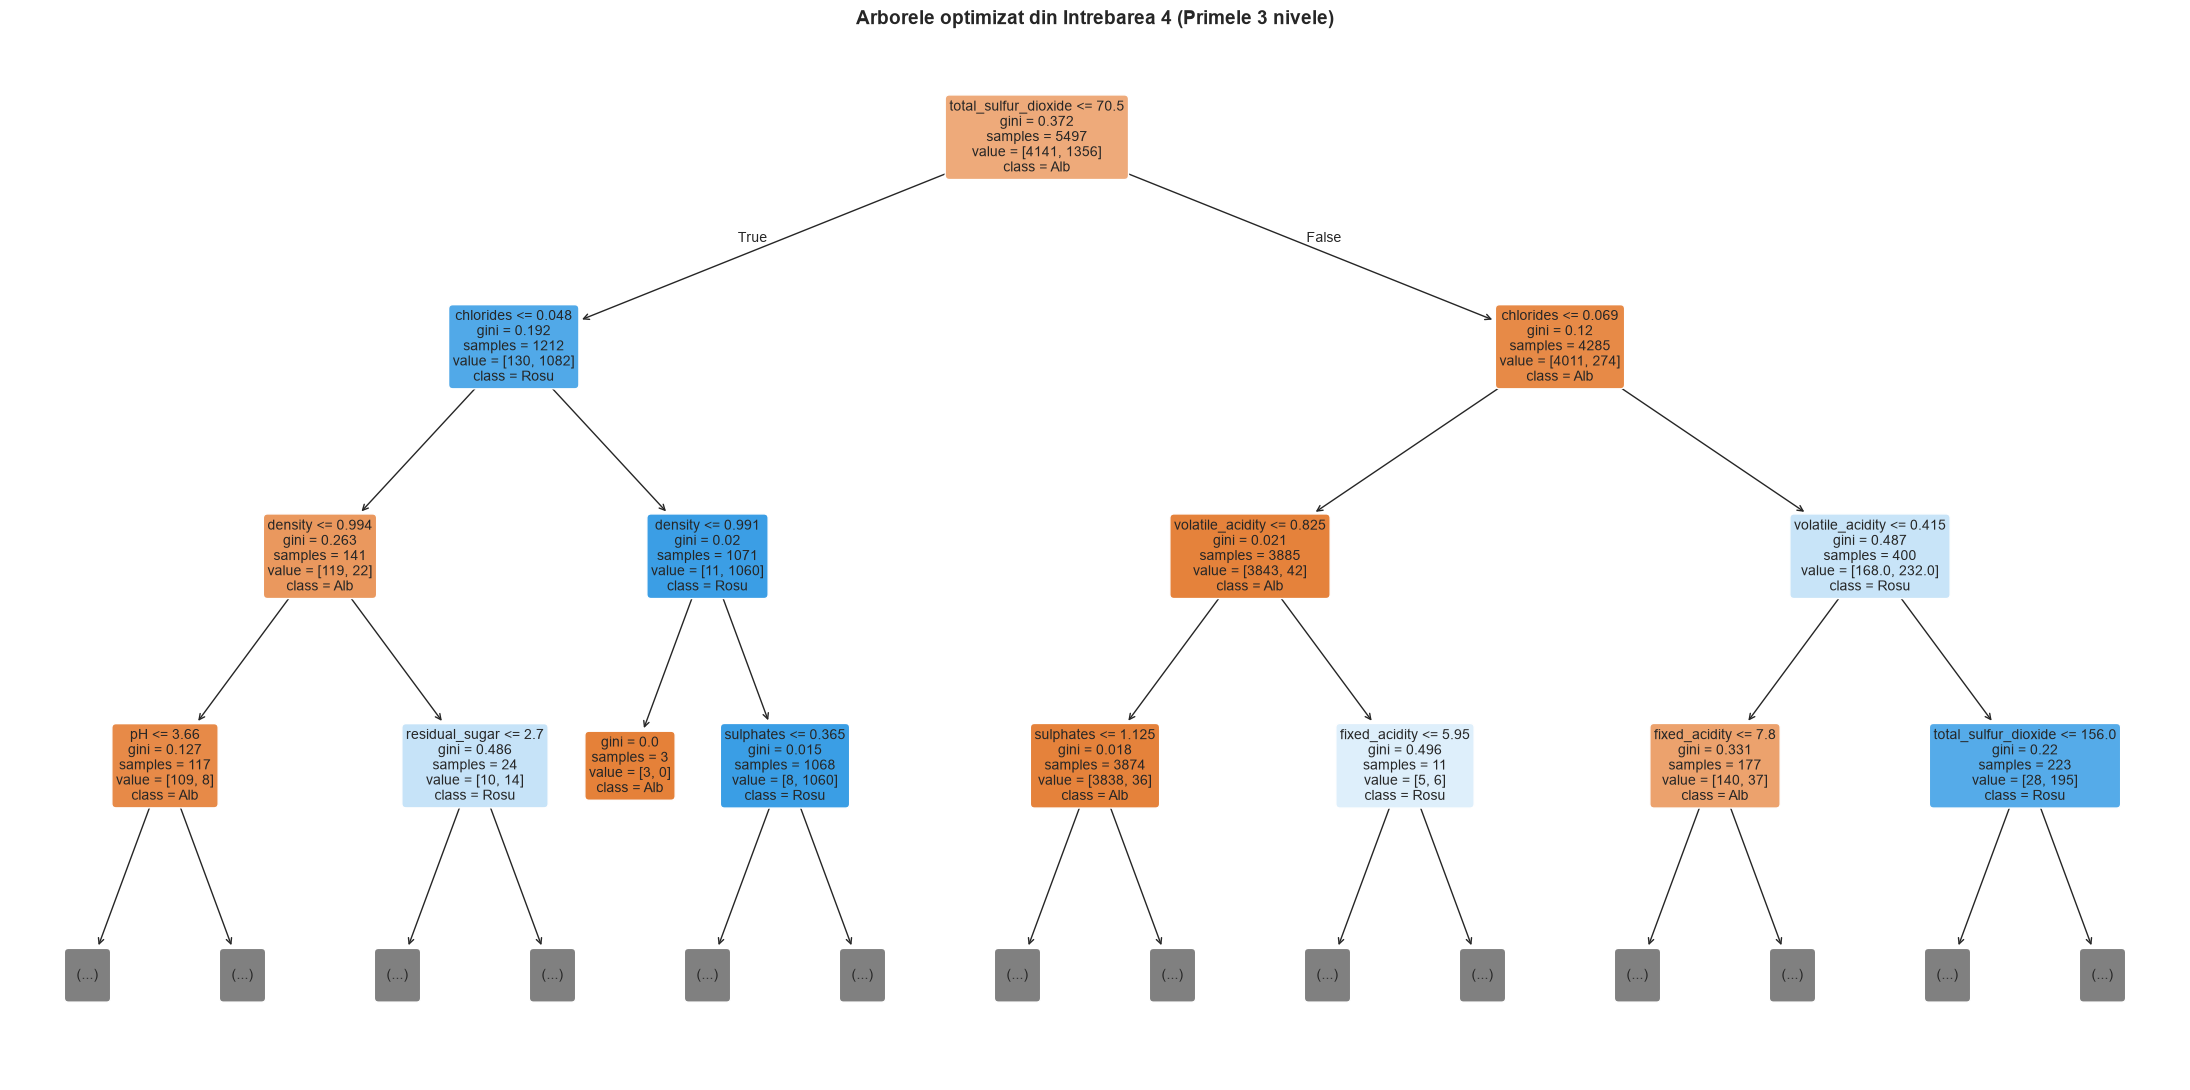

In [7]:
# Verificarea disponibilitatii PyDotPlus
try:
    import pydotplus
    pydotplus_installed = True
    print("PyDotPlus este instalat si disponibil.")
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

# Vizualizarea grafica nativa si robusta a arborilor folosind plot_tree din scikit-learn
# Aceasta metoda functioneaza direct in orice mediu, fara dependente externe de compilare

# 1. Vizualizarea primelor 3 nivele ale arborelui nerestrictionat din Intrebarea 3
plt.figure(figsize=(20, 10))
plot_tree(
    tree_classifier,
    max_depth=3,
    feature_names=feature_cols,
    class_names=['Alb', 'Rosu'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Arborele nerestrictionat din Intrebarea 3 (Primele 3 nivele)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Vizualizarea primelor 3 nivele ale arborelui optimizat din Intrebarea 4
plt.figure(figsize=(22, 11))
plot_tree(
    best_decision_tree,
    max_depth=3,
    feature_names=feature_cols,
    class_names=['Alb', 'Rosu'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Arborele optimizat din Intrebarea 4 (Primele 3 nivele)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# Generarea fisierelor DOT si integrarea cu PyDotPlus
dot_unconstrained = export_graphviz(
    tree_classifier,
    max_depth=3,
    feature_names=feature_cols,
    class_names=['Alb', 'Rosu'],
    filled=True,
    rounded=True,
    out_file=None
)

dot_cv = export_graphviz(
    best_decision_tree,
    max_depth=3,
    feature_names=feature_cols,
    class_names=['Alb', 'Rosu'],
    filled=True,
    rounded=True,
    out_file=None
)

print("Fragment din codul DOT generat pentru arborele optimizat:\n")
print(dot_cv[:400])

if pydotplus_installed:
    try:
        graph_cv = pydotplus.graph_from_dot_data(dot_cv)
        display(Image(graph_cv.create_png()))
        print("Graficul PNG generat de PyDotPlus a fost afisat cu succes.")
    except Exception as e:
        print(f"Nota: Binarul GraphViz nu a fost gasit in PATH ({e}). Graficele au fost randate direct prin matplotlib mai sus.")

Fragment din codul DOT generat pentru arborele optimizat:

digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label="total_sulfur_dioxide <= 70.5\ngini = 0.372\nsamples = 5497\nvalue = [4141, 1356]\nclass = Alb", fillcolor="#eeaa7a"] ;
1 [label="chlorides <= 0.048\ngini = 0.192\nsamples = 1212\nvalue = [130, 1082]\nclass = Rosu", fillcolor="#51a9e8"] ;
0 -> 1 [labeldistance=2.5,
Nota: Binarul GraphViz nu a fost gasit in PATH (GraphViz's executables not found). Graficele au fost randate direct prin matplotlib mai sus.


## Intrebarea 7 (Extensie): Comparatie cu Random Forest si Importanta Caracteristicilor

Pentru a completa studiul arborilor de decizie, comparam clasificatorul optimizat cu o padure de arbori decizionali (`RandomForestClassifier`).
* Antrenarea unui clasificator Random Forest pe aceleasi date.
* Evaluarea acuratetei pe test.
* Analiza importantei caracteristicilor (Gini Feature Importance).

Acuratete RandomForest pe setul de testare: 0.9990 (Eroare testare: 0.0010)


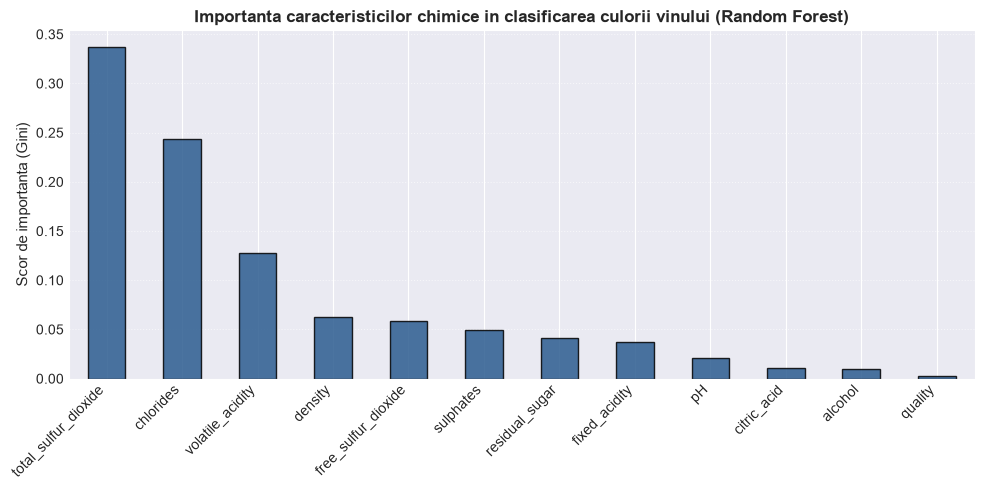

Clasamentul caracteristicilor dupa importanta:
total_sulfur_dioxide    0.3370
chlorides               0.2433
volatile_acidity        0.1276
density                 0.0622
free_sulfur_dioxide     0.0584
sulphates               0.0498
residual_sugar          0.0408
fixed_acidity           0.0373
pH                      0.0210
citric_acid             0.0103
alcohol                 0.0097
quality                 0.0027
dtype: float64


In [9]:
from sklearn.ensemble import RandomForestClassifier

# 1. Antrenarea clasificatorului Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_classifier.fit(X_train, y_train)

rf_test_acc = accuracy_score(y_test, rf_classifier.predict(X_test))
rf_test_err = 1.0 - rf_test_acc

print(f"Acuratete RandomForest pe setul de testare: {rf_test_acc:.4f} (Eroare testare: {rf_test_err:.4f})")

# 2. Analiza importantei caracteristicilor
importances = pd.Series(rf_classifier.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importances.plot(kind='bar', color='#2b5c8f', edgecolor='black', alpha=0.85)
ax = plt.gca()
ax.set_ylabel('Scor de importanta (Gini)', fontsize=11)
ax.set_title('Importanta caracteristicilor chimice in clasificarea culorii vinului (Random Forest)', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("Clasamentul caracteristicilor dupa importanta:")
print(importances.round(4))

### Concluzii generale ale laboratorului:
1. **Arborii de decizie nerestrictionati** sunt extrem de susceptibili la fenomenul de suprainvatare (overfitting), memorand fiecare inregistrare individuala din setul de antrenament.
2. **Optimizarea hiperparametrilor** prin tehnici de pre-prundare (`max_depth`, `min_samples_leaf`) imbunatateste considerabil performanta pe date noi si reduce complexitatea structurala a modelului.
3. **Arborii de regresie** partitioneaza spatiul continuu in regiuni omogene, aproximand cu succes variabile continue neliniare (cum este `residual_sugar`).
4. **Analiza importantei caracteristicilor** arata ca `total_sulfur_dioxide` si `volatile_acidity` sunt cele mai determinante caracteristici chimice pentru identificarea tipului de vin.